# Cross sections — liquid water

**NJOY**

Analyze the CAB liquid-water model at 295 K. TARA uses the reference and three stochastic realizations of the hydrogen continuum to calculate and plot the available cross-section channels. Each step identifies its **required inputs** and **optional settings**.

This workflow runs LEAPR and THERMR directly from the template and the base neutron evaluation.

**NCrystal**

Analyze the illustrative liquid-water model at 295 K. TARA uses the reference and three stochastic realizations of the hydrogen VDOS to calculate and plot the available cross-section channels. Each step identifies its **required inputs** and **optional settings**.

This workflow evaluates on-the-fly scattering with the NCrystal Liquids plugin. The water NCMAT is illustrative.

## 0. Choose the engine

**Required setting**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `ENGINE` | `"ncrystal"` | Select `"njoy"` or `"ncrystal"` for this run. |

After changing the engine, restart the kernel and run all cells.

In [1]:
AVAILABLE_ENGINE = ("njoy", "ncrystal")
AVAILABLE_ENGINE_LABEL = {
    "njoy": "NJOY",
    "ncrystal": "NCrystal"
}

In [2]:
ENGINE = "ncrystal"
if ENGINE not in AVAILABLE_ENGINE:
    raise ValueError('Choose ENGINE = "njoy" or "ncrystal".')
ENGINE_LABEL = AVAILABLE_ENGINE_LABEL[ENGINE]

## 1. Locate TARA

The next cell finds TARA and imports the APIs for the chosen engine.

In [3]:
from pathlib import Path
import os
import shutil
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "core" / "config.py").is_file()
     and (path / "processing" / "pipelines" / "ace_pipeline.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the TARA repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import parallel_execution
from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler

if ENGINE == "njoy":
    from input_output.leapr.core import LeaprFile
    from input_output.leapr.material_adapter import material_model_from_leapr
elif ENGINE == "ncrystal":
    from input_output.ncrystal.core import NCrystalFile
    from input_output.ncrystal.liquids import load_liquid_ncmat, parse_custom_liquids

## 2. Select the required inputs

| Setting | Example value | What it controls |
| --- | --- | --- |
| `BASE_LEAPR_FILE` | `tests/fixtures/tsl-HinH2O.leapr` | NJOY material template. |
| `BASE_NCMAT_FILE` | `tests/fixtures/liquid_water_295K_illustrative.ncmat` | NCrystal material. |
| `BASE_ENDF_FILE` | `tests/fixtures/n_1-H-001g.jeff` | Neutron evaluation for the NJOY path. Override with `TARA_BASE_ENDF` if needed. |
| `NJOY_EXECUTABLE` | `NJOY_EXEC` or `njoy` on `PATH` | Executable for the NJOY path. |

Edit paths only if your checkout or NJOY installation uses different locations.

NCrystal liquid calculations require the Liquids plugin.

In [4]:
fixtures = PROJECT_ROOT / "tests" / "fixtures"
BASE_ENDF_FILE = Path(os.environ.get("TARA_BASE_ENDF", str(fixtures / "n_1-H-001g.jeff")))
njoy_path = shutil.which(os.environ.get("NJOY_EXEC") or "njoy")
NJOY_EXECUTABLE = Path(njoy_path) if njoy_path else None

if ENGINE == "njoy":
    if not BASE_ENDF_FILE.is_file() or BASE_ENDF_FILE.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty neutron ENDF: {BASE_ENDF_FILE}")
    if NJOY_EXECUTABLE is None:
        raise FileNotFoundError("Set NJOY_EXEC or add njoy to PATH.")

    print("Neutron ENDF:", BASE_ENDF_FILE)
    print("NJOY:", NJOY_EXECUTABLE)

In [5]:
if ENGINE == "njoy":
    BASE_LEAPR_FILE = fixtures / "tsl-HinH2O.leapr"
    if not BASE_LEAPR_FILE.is_file():
        raise FileNotFoundError(f"LEAPR template missing: {BASE_LEAPR_FILE}")
elif ENGINE == "ncrystal":
    BASE_NCMAT_FILE = fixtures / "liquid_water_295K_illustrative.ncmat"
    if not BASE_NCMAT_FILE.is_file():
        raise FileNotFoundError(f"NCMAT template missing: {BASE_NCMAT_FILE}")

## 3. Load the liquid water reference

**Fixed settings for this example**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `TEMPERATURE_K` | `295` | Evaluation temperature in kelvin. |
| `ATOM_LABEL` | `"H"` | Species supplying the reference spectrum. |

In [6]:
TEMPERATURE_K = 295.0
ATOM_LABEL = "H"
print(f"Engine: {ENGINE_LABEL}")
print(f"temperature: {TEMPERATURE_K:g} K")

if ENGINE == "njoy":
    template = LeaprFile.from_file(str(BASE_LEAPR_FILE))
    leapr_template = template

    material = material_model_from_leapr(
        template, state="liquid", temperature=TEMPERATURE_K,
        principal_label=ATOM_LABEL, secondary_label="O",
    )
    if (material.principal.multiplicity != 2 or len(material.secondary) != 1
            or material.secondary[0].multiplicity != 1):
        raise ValueError("Expected the CAB H-in-water LEAPR material.")
    dynamics = material.dynamics
    reference_spectrum = dynamics.continuous
    raw_pdos = reference_spectrum.pdos
    vibrational_weight = dynamics.continuous_weight + sum(
        oscillator.weight for oscillator in dynamics.oscillators
    )
    translation_weight = dynamics.translation_weight
    print(f"LEAPR file: {BASE_LEAPR_FILE}")
elif ENGINE == "ncrystal":
    source_text = load_liquid_ncmat(BASE_NCMAT_FILE)
    liquid_entries = parse_custom_liquids(source_text)
    liquid_settings = next((entry for entry in liquid_entries if entry.atom == ATOM_LABEL), None)
    if liquid_settings is None:
        raise ValueError(f"No custom liquid settings for {ATOM_LABEL!r}.")
    vibrational_weight = liquid_settings.ws
    translation_weight = liquid_settings.wt

    material = NCrystalFile.from_file(str(BASE_NCMAT_FILE))
    raw_pdos = material.pdos_for_atom(ATOM_LABEL)
    reference_spectrum = PhononSpectra(pdos=raw_pdos)
    print(f"NCMAT file: {BASE_NCMAT_FILE}")

print(f"Vibrational weight: {vibrational_weight:g}")
print(f"Translation weight: {translation_weight:g}")

Engine: NCrystal
temperature: 295 K
NCMAT file: /home/aitor/postdoc/tara_preview_V3_5/tests/fixtures/liquid_water_295K_illustrative.ncmat
Vibrational weight: 0.99197
Translation weight: 0.0080324


## 4. Sample the vibrational spectrum

**Required:** The reference material from Section 3 and the two perturbation bounds below. Select a positive sample count for the comparison.

**Required sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `5.0` | Maximum phonon-energy displacement in meV. |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative PDOS amplitude change in percent. |
| `N_SAMPLES` | `3` | Number of stochastic samples. The reference is stored separately. |

**NJOY**

The CAB oscillator and translation parameters are retained.

**NCrystal**

The NCMAT liquid settings are retained.

In [7]:
MAX_ENERGY_SHIFT_MEV = 5.0
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 3

**Optional sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RANDOM_SEED` | `20261014` | Seed for reproducible sampling. |
| `BATCH_SIZE` | `512` | Internal sampling chunk size. |
| `AMPLITUDE_METHOD` | `"fast"` | Method used for the amplitude perturbations. |
| `SPATIAL_METHOD` | `"diffeomorphic"` | Method used to shift the spectrum in energy. |

In [8]:
RANDOM_SEED = 20261014
BATCH_SIZE = 512
AMPLITUDE_METHOD = "fast"
SPATIAL_METHOD = "diffeomorphic"

In [9]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
    random_seed=RANDOM_SEED,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

# Generate the stochastic ensemble with the configured sampling batch size.
ensemble = sampler.generate_ensemble(batch_size=BATCH_SIZE)
if ensemble.reference is None or len(ensemble) != N_SAMPLES:
    raise RuntimeError("Expected the reference and all requested samples.")
print(f"Prepared one reference and {len(ensemble)} stochastic spectra.")

Prepared one reference and 3 stochastic spectra.


## 5. Configure the Analyzer and request cross sections

**NJOY**

**Required:** The material from Section 3 and the ensemble from Section 4. The NJOY Analyzer runner uses the first positive LEAPR block. For this water example, prepare a temporary one-temperature template from the selected CAB block so the runner retains its diffusion and oscillator parameters.

**Optional settings:** All samples are selected. Adjust the observable settings below or the optional THERMR settings in Section 6.

**NCrystal**

**Required:** The material from Section 3 and the ensemble from Section 4. The Analyzer uses a temporary capture adapter to obtain the completed liquid kernel and native cross sections. The build directory stays available through Section 6.

**Optional settings:** All samples are selected. The capture resolution and observable requests can be adjusted in this section. Leave `vdoslux=0` for this short example.

In [10]:
import numpy as np
from analyzer.ensemble_analyzer import EnsembleAnalyzer

if ENGINE == "njoy":
    import tempfile
    from endf_parserpy import EndfParserPy
    from scipy.constants import physical_constants
    from input_output.leapr.workflows import serialize_leapr_spectrum
    from analyzer.parsers.njoy_parser import NjoyParser
    from analyzer.runners.njoy_runner import NjoyRunner

    base_header = EndfParserPy().parsefile(str(BASE_ENDF_FILE), include=[1])[1][451]
    if int(round(float(base_header["ZA"]))) != 1001:
        raise ValueError("Expected base neutron evaluation ZA=1001.")
    MASS_AMU = float(template.principal_scatterer["awr"]) * physical_constants["neutron mass in u"][0]
elif ENGINE == "ncrystal":
    from analyzer.parsers.ncrystal_parser import NCrystalParser
    from analyzer.runners.ncrystal_runner import NCrystalRunner

In [11]:
# Configure the appropriate engine runner and parser based on the selected ENGINE.
if ENGINE == "njoy":
    leapr_temp_dir = tempfile.TemporaryDirectory(prefix="tara_cab_water_")
    selected_leapr_path = Path(leapr_temp_dir.name) / "cab_water_selected.leapr"
    selected_leapr_path.write_text(
        serialize_leapr_spectrum(
            template, reference_spectrum, temperature=TEMPERATURE_K,
            preserve_temperature_parameters=True,
        ),
        encoding="utf-8",
    )
    runner = NjoyRunner(
        njoy_exec=str(NJOY_EXECUTABLE),
        base_endf_file=str(BASE_ENDF_FILE),
        base_leapr_file=str(selected_leapr_path),
        temperature=TEMPERATURE_K,
        mass_amu=MASS_AMU,
    )
    parser = NjoyParser()
elif ENGINE == "ncrystal":
    runner = NCrystalRunner(
        base_ncmat_file=str(BASE_NCMAT_FILE),
        temperature=TEMPERATURE_K,
    )
    parser = NCrystalParser()

In [12]:
# Initialize the ensemble analyzer with the generated ensemble, runner, and parser.
analyzer = EnsembleAnalyzer(
    ensemble=ensemble,
    runner=runner,
    parser=parser
)

**Optional observable settings**

**NJOY**

Cross sections are in **barns** and incident neutron energies are in **eV**. The NJOY parser reports the available THERMR thermal-scattering total and its components. Its total excludes absorption. The CAB liquid example has no separate elastic channel.

**NCrystal**

Cross sections are in **barns** and incident neutron energies are in **eV**. The native total and inelastic curves describe the full illustrative water material. They include the hydrogen liquid kernel and the free-gas oxygen scattering. Absorption is separate. This model has no separate elastic scattering channels.

| Setting | Example value | What it controls |
| --- | --- | --- |
| `EVAL_ENERGY_GRID` | `np.geomspace(1e-5, 1.0, 180)` | **NJOY** Incident neutron energies used to report the selected channels.<br>**NCrystal** Evaluation energies shared by the native runner and parser. |
| `calc_xs_total` | `True` | **NJOY** Total thermal scattering available from THERMR.<br>**NCrystal** Native total scattering. |
| `calc_xs_inelastic` | `True` | **NJOY** Thermal inelastic scattering.<br>**NCrystal** Native inelastic scattering. |
| `calc_xs_absorption` | `True` | **NCrystal**. Material absorption. |

In [13]:
EVAL_ENERGY_GRID = np.geomspace(1e-5, 1.0, 180)

parser_kwargs = dict(
    energy_grid=EVAL_ENERGY_GRID,
    calc_xs_total=True,
    calc_xs_inelastic=True,
    calc_xs_elastic=False,
)

if ENGINE == "ncrystal":
    parser_kwargs["calc_xs_absorption"] = True

## 6. Run the Analyzer

**NJOY**

**Required:** The Analyzer and observable settings from Section 5. Evaluate the reference separately to enable the relative comparisons in Section 7.

**Optional execution and THERMR settings:**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RUN_PARALLEL` | `False` | Run sequentially or request concurrent processing. |
| `thermr_emax` | `5.0` | Upper THERMR processing energy in eV. |
| `thermr_tol` | `0.05` | THERMR interpolation tolerance. |
| `thermr_nbin` | `16` | THERMR angular bin count. |

**NCrystal**

**Required:** The Analyzer and observable settings from Section 5 and the atom label from Section 3. Pass the same evaluation grid to the native runner and parser. Evaluate the reference separately to enable the relative comparisons in Section 7.

**Optional:** Set `RUN_PARALLEL=True` to request concurrent processing. The example runs sequentially.

In [ ]:
RUN_PARALLEL = False

if ENGINE == "njoy":
    RUNNER_OPTIONS = {
        "thermr_emax": 5.0,
        "thermr_tol": 0.05,
        "thermr_nbin": 16,
    }
elif ENGINE == "ncrystal":
    RUNNER_OPTIONS = {
        "atom_label": ATOM_LABEL,
        "energy_grid": EVAL_ENERGY_GRID
    }

In [15]:
# Compute the ensemble results using the configured analyzer.
analyzer.compute(
    parallel=RUN_PARALLEL,
    runner_kwargs=RUNNER_OPTIONS,
    parser_kwargs=parser_kwargs,
    compute_reference=True,
)

if analyzer.reference_result is None or len(analyzer.raw_results) != len(ensemble):
    raise RuntimeError("The Analyzer did not return the expected reference and sample results.")
print(f"Analyzed one reference and {len(analyzer.raw_results)} stochastic spectra.")

Analyzed one reference and 3 stochastic spectra.


## 7. Plot the cross sections

**NJOY**

**Required:** The reference and sample results from Section 6. Each plot shows the phonon spectra (energy in meV), the cross section (barns versus incident energy in eV), and the percentage difference from the reference:
$100,(sigma_{mathrm{sample}}-sigma_{mathrm{ref}})/sigma_{mathrm{ref}}$.

**Optional settings:** None. To change which channels are calculated, return to Section 5.

The plotting cell skips unavailable channels. Relative differences are undefined wherever the reference cross section is zero.

**NCrystal**

**Required:** The reference and sample results from Section 6. First inspect the three regions of the vibrational spectrum. Then compare each available cross section in barns against incident neutron energy in eV.

**Optional settings:** None. Return to Section 5 to change which channels are calculated.

The cross-section plots include the percentage difference from the reference,
$100\,(\sigma_{\mathrm{sample}}-\sigma_{\mathrm{ref}})/\sigma_{\mathrm{ref}}$.
Unavailable channels are skipped. The percentage difference is undefined where the reference cross section is zero.

In [16]:
from notebooks.tara_plotting import plot_water_master_dashboard


def show_cross_section_channel(channel, label):
    """Plot a channel when both reference and sample data are available."""
    reference = getattr(analyzer.reference_result.integ, channel)
    if reference is None or not any(
        getattr(result.integ, channel) is not None for result in analyzer.raw_results
    ):
        print(f"{label}: unavailable for this calculation.")
        return

    plot_water_master_dashboard(
        data_obj=analyzer,
        ref_label=f"{ENGINE_LABEL} reference",
        main_title=label,
        xs_type=channel,
        plot_pdos=True,
        plot_xs=True,
        plot_error=True,
    )

### 7.1. Total thermal scattering cross section

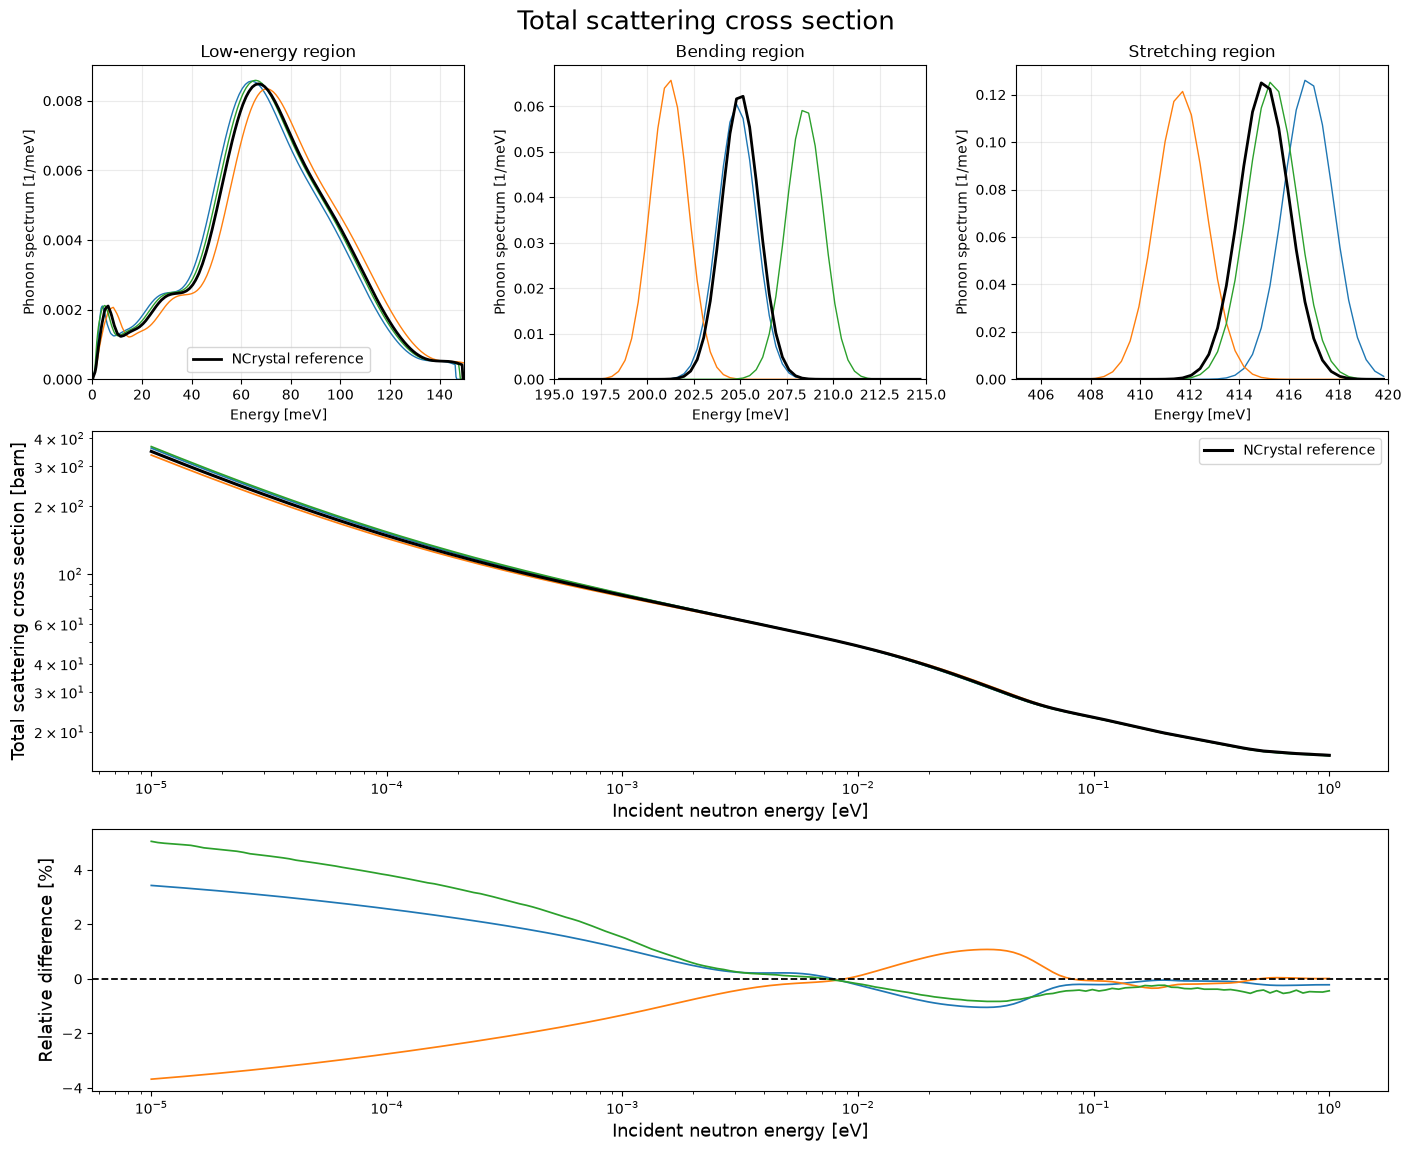

In [17]:
if ENGINE == "njoy":
    total_label = "Total thermal scattering cross section"
elif ENGINE == "ncrystal":
    total_label = "Total scattering cross section"

show_cross_section_channel("xs_total", total_label)

### 7.2. Inelastic scattering cross section

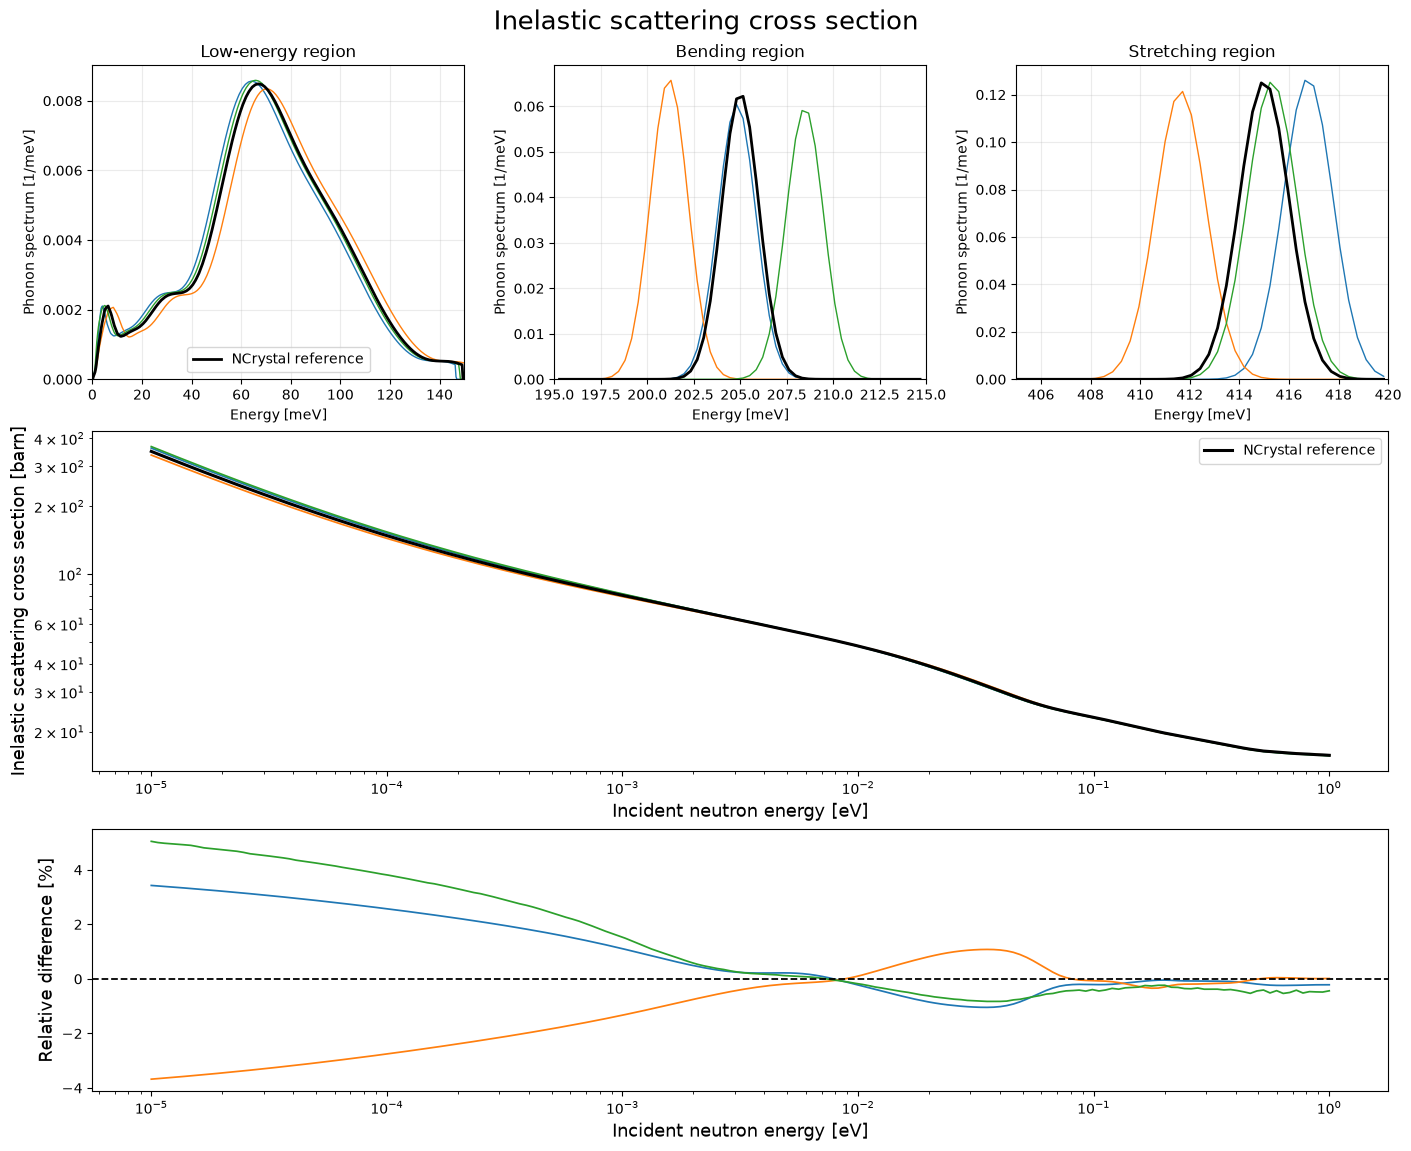

In [18]:
show_cross_section_channel("xs_inelastic", "Inelastic scattering cross section")